# Salifort Motors: Employee Attrition

## Plan
Understand observed departure patterns and compare predictive models. This notebook follows the PACE framework and complements the executive report and presentation. The supplied original notebook is preserved separately.

**Success metric:** validation average precision, with held-out precision, recall, F1, ROC AUC and a confusion matrix. Results are retrospective; no prediction horizon or intervention costs were supplied.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
from analysis import load_data, explore, train_models
from IPython.display import display, Image, Markdown
import pandas as pd

## Analyze: quality and cleaning
Exact duplicate records are removed **before splitting** so identical rows do not appear across splits. There are no employee identifiers, so confirm that these are duplicate observations rather than distinct employees. Compare raw and cleaned attrition rates. All valid tenure values are retained.

In [2]:
df, audit = load_data()
display(df.head())
display(df.describe(include="all").T)

{
  "raw_rows": 14999,
  "columns": 10,
  "duplicate_rows": 3008,
  "missing_cells": 0,
  "raw_attrition_rate": 0.2380825388359224,
  "clean_rows": 11991,
  "attrition_rate": 0.1660411975648403
}


,satisfaction_level,last_evaluation,number_project,average_monthly_hours,tenure,work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
satisfaction_level,11991.0,NaN,NaN,NaN,0.629658,0.24107,0.09,0.48,0.66,0.82,1.0
last_evaluation,11991.0,NaN,NaN,NaN,0.716683,0.168343,0.36,0.57,0.72,0.86,1.0
number_project,11991.0,NaN,NaN,NaN,3.802852,1.163238,2.0,3.0,4.0,5.0,7.0
average_monthly_hours,11991.0,NaN,NaN,NaN,200.473522,48.727813,96.0,157.0,200.0,243.0,310.0
tenure,11991.0,NaN,NaN,NaN,3.364857,1.33024,2.0,3.0,3.0,4.0,10.0
work_accident,11991.0,NaN,NaN,NaN,0.154282,0.361234,0.0,0.0,0.0,0.0,1.0
left,11991.0,NaN,NaN,NaN,0.166041,0.372133,0.0,0.0,0.0,0.0,1.0
promotion_last_5years,11991.0,NaN,NaN,NaN,0.016929,0.129012,0.0,0.0,0.0,0.0,1.0
department,11991,10,sales,3239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary,11991,3,low,5740,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Analyze: exploratory findings
Group rates and distributions describe associations; differences do not demonstrate causal effects.

Group-level tables and exploratory figures saved.


### Department

,employees,leavers,attrition_rate
department,,,
IT,976,158,0.161885
RandD,694,85,0.122478
accounting,621,109,0.175523
hr,601,113,0.188020
management,436,52,0.119266
marketing,673,112,0.166419
product_mng,686,110,0.160350
sales,3239,550,0.169805
support,1821,312,0.171334


### Salary

,employees,leavers,attrition_rate
salary,,,
high,990,48,0.048485
low,5740,1174,0.204530
medium,5261,769,0.146170


### Number Project

,employees,leavers,attrition_rate
number_project,,,
2,1582,857,0.541719
3,3520,38,0.010795
4,3685,237,0.064315
5,2233,343,0.153605
6,826,371,0.449153
7,145,145,1.000000


### Tenure

,employees,leavers,attrition_rate
tenure,,,
2,2910,31,0.010653
3,5190,874,0.168401
4,2005,495,0.246883
5,1062,482,0.453861
6,542,109,0.201107
7,94,0,0.000000
8,81,0,0.000000
10,107,0,0.000000


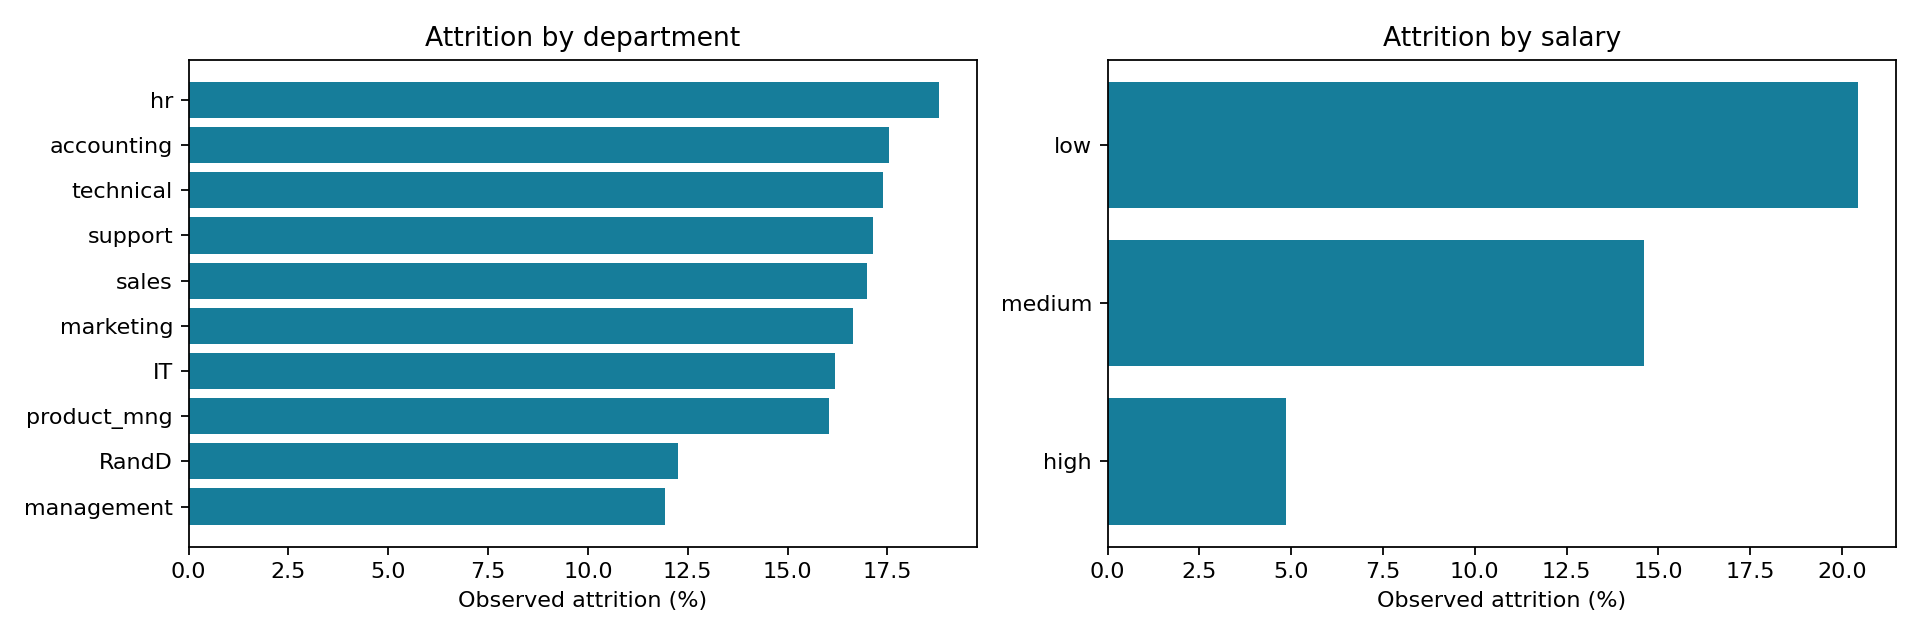

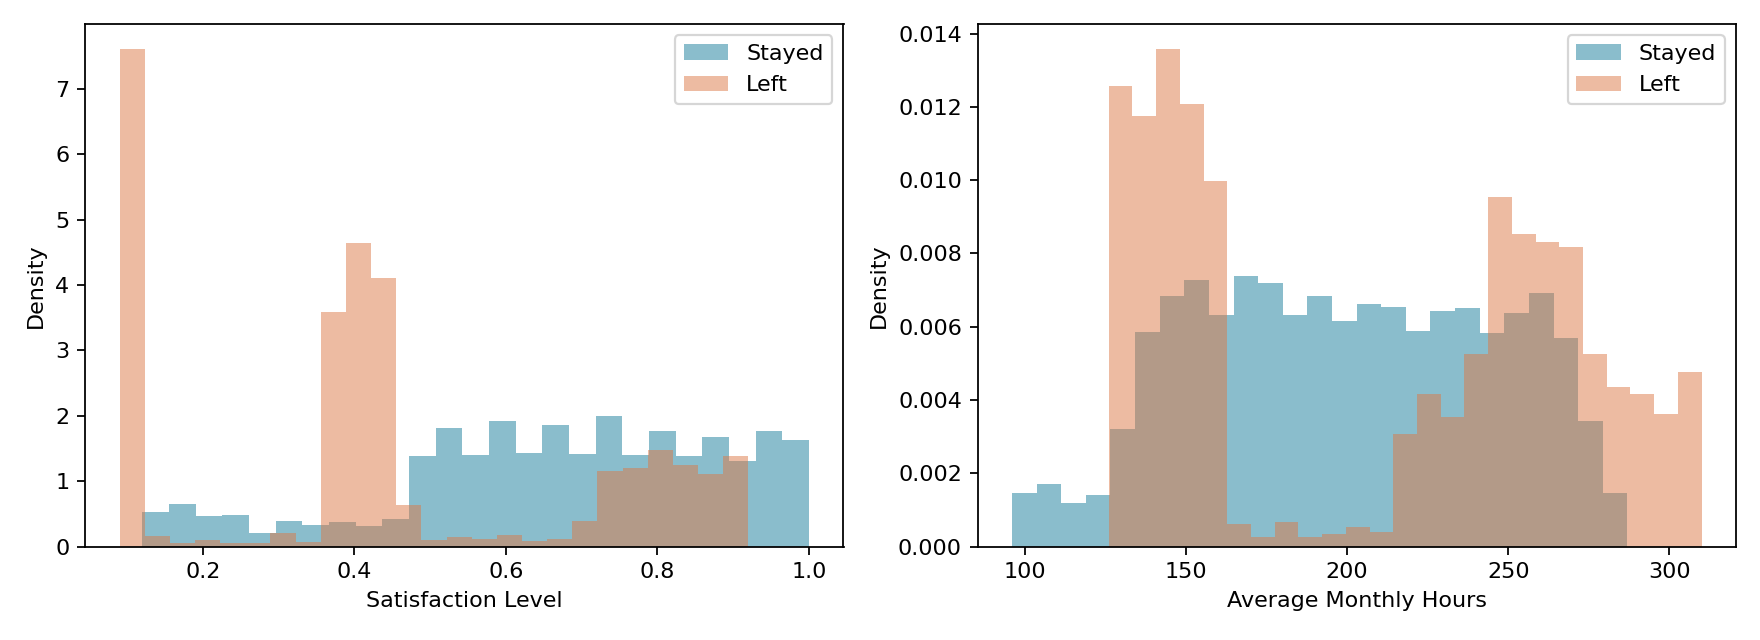

In [3]:
tables = explore(df)
for name, table in tables.items():
    display(Markdown('### ' + name.replace('_', ' ').title()))
    display(table)
for name in ['attrition_groups.png', 'workload_satisfaction.png']:
    display(Image(filename=str(ROOT / 'reports/figures' / name)))

## Construct: model comparison
Stratified 60/20/20 train/validation/test split, seed 42. Pipelines fit imputation, scaling and categorical encoding on training data. Compare a dummy baseline, logistic regression, depth-limited tree and random forest. Select the highest validation average precision; refit on training plus validation; evaluate once on held-out test at threshold 0.5. Permutation importance uses validation data before refitting. No test-set tuning is performed.

In [4]:
results, comparison, importance = train_models(df)
display(comparison)
display(importance)

Dummy baseline {'model': 'Dummy baseline', 'accuracy': 0.8340283569641368, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'roc_auc': 0.5, 'average_precision': 0.16597164303586323}


Logistic regression {'model': 'Logistic regression', 'accuracy': 0.8381984987489575, 'precision': 0.5308641975308642, 'recall': 0.21608040201005024, 'f1': 0.30714285714285716, 'roc_auc': 0.8262437185929649, 'average_precision': 0.42924224595251537}


Decision tree {'model': 'Decision tree', 'accuracy': 0.9770642201834863, 'precision': 0.9454545454545454, 'recall': 0.914572864321608, 'f1': 0.929757343550447, 'roc_auc': 0.9791407035175879, 'average_precision': 0.9439749480594908}


Random forest {'model': 'Random forest', 'accuracy': 0.9804003336113428, 'precision': 0.9782016348773842, 'recall': 0.9020100502512562, 'f1': 0.938562091503268, 'roc_auc': 0.9897939698492463, 'average_precision': 0.9712408655064765}


{
  "selected_model": "Random forest",
  "threshold": 0.5,
  "split": {
    "train": 7194,
    "validation": 2398,
    "test": 2399
  },
  "test_metrics": {
    "accuracy": 0.9829095456440183,
    "precision": 0.9811320754716981,
    "recall": 0.914572864321608,
    "f1": 0.9466840052015605,
    "roc_auc": 0.9796458554642277,
    "average_precision": 0.9638667940006974
  },
  "confusion_matrix": [
    [
      1994,
      7
    ],
    [
      34,
      364
    ]
  ],
  "test_prevalence": 0.16590245935806586,
  "test_ap_bootstrap_95_ci": [
    0.9482755337356816,
    0.9772581000929307
  ],
  "seed": 42
}


,model,accuracy,precision,recall,f1,roc_auc,average_precision
3,Random forest,0.980400,0.978202,0.902010,0.938562,0.989794,0.971241
2,Decision tree,0.977064,0.945455,0.914573,0.929757,0.979141,0.943975
1,Logistic regression,0.838198,0.530864,0.216080,0.307143,0.826244,0.429242
0,Dummy baseline,0.834028,0.000000,0.000000,0.000000,0.500000,0.165972


,feature,mean_ap_decrease,std
0,satisfaction_level,0.276132,0.013976
4,tenure,0.129472,0.003975
2,number_project,0.074673,0.006948
3,average_monthly_hours,0.069685,0.004283
1,last_evaluation,0.046264,0.007050
8,salary,0.004990,0.001129
5,work_accident,0.001060,0.000369
7,department,0.000517,0.001234
6,promotion_last_5years,0.000113,0.000052


## Execute: performance and interpretation
The bootstrap interval conditions on the fitted model. It does not measure uncertainty from training or future changes in the employee population.

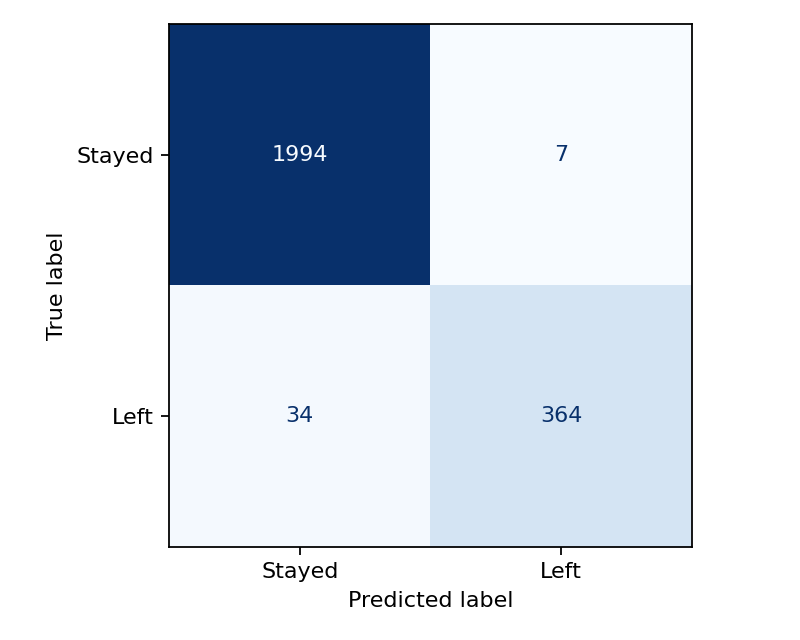

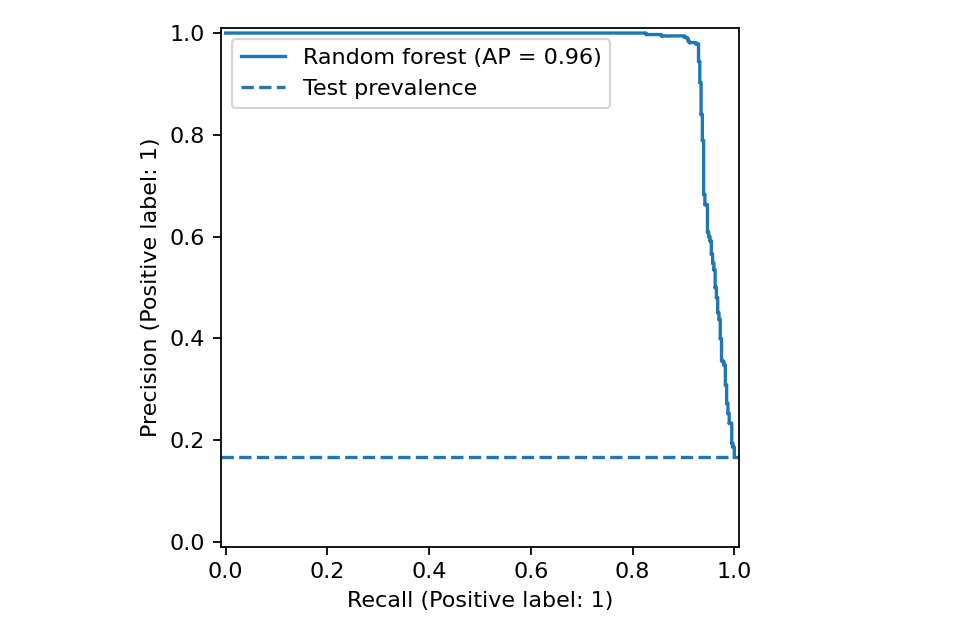

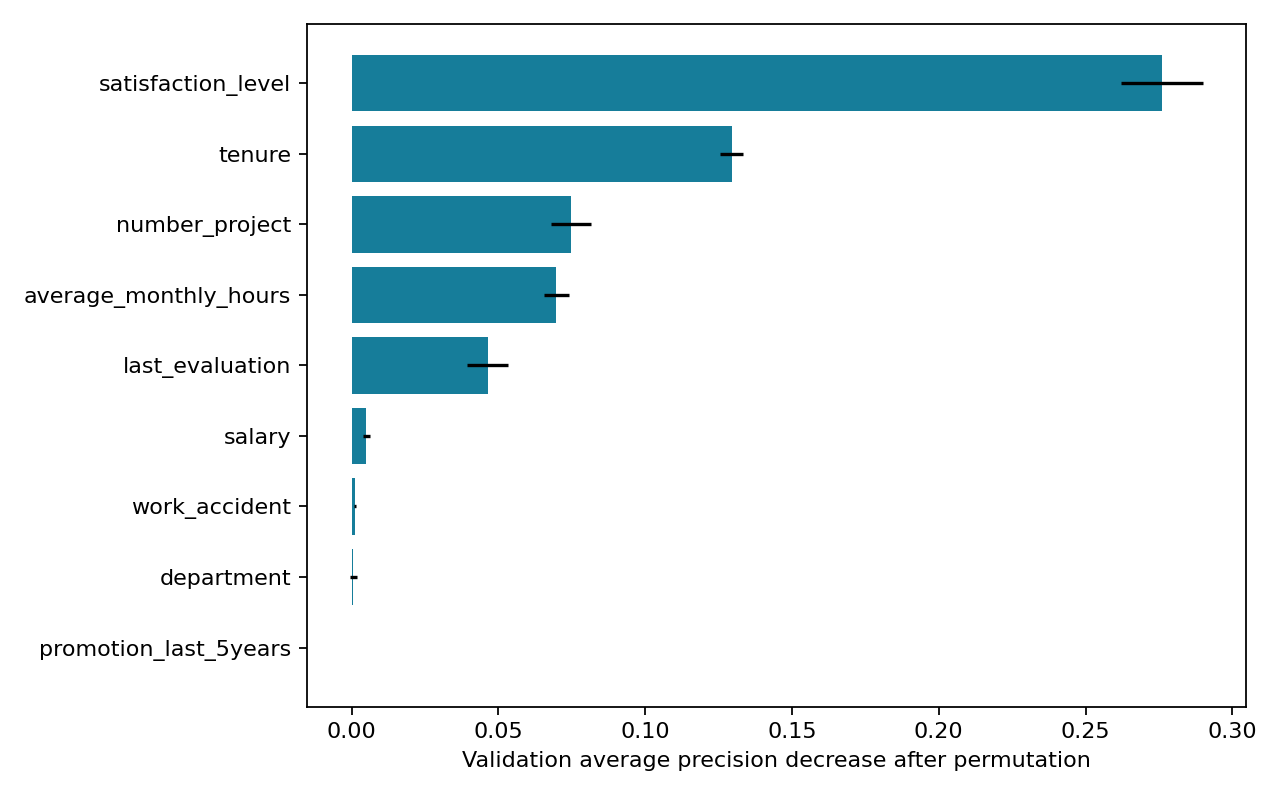

Executive report (Markdown/DOCX) and 10-slide PowerPoint saved.


In [5]:
for name in ['confusion_matrix.png','precision_recall.png','feature_importance.png']:
    display(Image(filename=str(ROOT / 'reports/figures' / name)))
from build_deliverables import main
main()

## Recommendations and limitations
Investigate extreme workloads and project assignments through confidential employee feedback. Pilot voluntary support and measure retention and wellbeing against a defined comparison group. Audit compensation and progression opportunities.

The data has no documented provenance, collection dates, employee IDs, or license in the uploaded ZIP. Confirm redistribution rights before public publication. Satisfaction and evaluation timing may make them unsuitable for an early-warning system. Validate on a later employee cohort, assess subgroup fairness and probability calibration, and define intervention costs before operational use. Model importance is predictive, not causal.

The executive report, PowerPoint, metrics, and figures are generated in `reports/`.